# Milestone 2 — Who shops here? (pandas exploration)

Goal: pull `ecom` customer + order data into pandas and build a first-pass mental model
before RFM feature engineering in Milestone 3.

Setup (run once from the repo root):
```
source .venv/bin/activate
export DATABASE_URL='postgresql://ecom_ro_user:<password>@<neon-host>:5432/neondb?sslmode=require'
```
The notebook reads the URL from `DATABASE_URL` so no credential is committed.
The customer aggregation below mirrors `sql/01_customer_level_base.sql`.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import sqlalchemy as sa

db_url = os.environ.get("DATABASE_URL")
assert db_url, "Set DATABASE_URL to your Topfolio connection string first."
engine = sa.create_engine(db_url)
print("engine ready")

engine ready


## 1. Confirm the connection with a small sample

Cheap queries first: five earliest orders and five customers. I only proceed
once these return.

In [2]:
sample_orders = pd.read_sql(
    sa.text(
        "SELECT order_id, customer_id, created_at, status, payment_status, total "
        "FROM ecom.orders ORDER BY created_at LIMIT 5"
    ),
    engine,
)
sample_orders


,order_id,customer_id,created_at,status,payment_status,total
0,36,8801,2026-03-16 00:13:57+00:00,delivered,paid,22530.92
1,19,6192,2026-03-16 00:53:05+00:00,paid,paid,17814.46
2,110,5380,2026-03-16 01:10:06+00:00,shipped,paid,4482.82
3,142,6957,2026-03-16 01:56:28+00:00,delivered,paid,2956.64
4,39,6444,2026-03-16 02:09:22+00:00,Shipped,paid,5660.46


In [3]:
sample_customers = pd.read_sql(
    sa.text(
        "SELECT customer_id, created_at, lifecycle_stage, acquisition_channel "
        "FROM ecom.customers ORDER BY customer_id LIMIT 5"
    ),
    engine,
)
sample_customers


,customer_id,created_at,lifecycle_stage,acquisition_channel
0,1,2026-05-29 16:30:14+00:00,active,organic
1,2,2026-06-05 01:03:31+00:00,at_risk,organic
2,3,2026-05-29 19:16:28+00:00,active,organic
3,4,2026-06-13 15:31:10+00:00,at_risk,paid
4,5,2026-05-31 06:37:14+00:00,at_risk,referral


Connection works. Next: one row per customer.
I aggregate in SQL (faster than pulling 40k orders into pandas) and keep
**paid orders only** — cancelled/failed payments would distort spend.

In [4]:
customers = pd.read_sql(
    sa.text(
        """
        SELECT o.customer_id,
               COUNT(*) AS order_count,
               SUM(o.total) AS total_spend,
               MIN(o.created_at) AS first_order_date,
               MAX(o.created_at) AS last_order_date
        FROM ecom.orders AS o
        WHERE o.payment_status = 'paid'
        GROUP BY o.customer_id
        """
    ),
    engine,
)
print(f"paid customers: {len(customers)}")
customers.head()

paid customers: 8438


,customer_id,order_count,total_spend,first_order_date,last_order_date
0,6114,1,4835.64,2026-05-30 05:16:02+00:00,2026-05-30 05:16:02+00:00
1,4790,2,14033.74,2026-04-02 18:10:41+00:00,2026-04-02 21:33:39+00:00
2,3936,4,39577.20,2026-03-22 09:22:37+00:00,2026-04-04 14:35:03+00:00
3,5761,6,51488.12,2026-04-05 06:54:45+00:00,2026-05-02 23:24:39+00:00
4,5468,1,4126.46,2026-04-29 05:06:41+00:00,2026-04-29 05:06:41+00:00


## 2. Describe: what is normal?

`describe()` plus an explicit median-vs-mean check — with skewed spend,
the mean alone misleads (more on that in the findings note).

In [5]:
customers[["total_spend", "order_count"]].describe()


,total_spend,order_count
count,8.438000e+03,8438.000000
mean,3.352207e+04,4.482342
std,7.481215e+04,9.470045
min,1.758200e+02,1.000000
25%,3.891640e+03,1.000000
50%,1.209087e+04,1.000000
75%,3.775248e+04,5.000000
max,1.335804e+06,168.000000


In [6]:
print("median spend:", customers["total_spend"].median())
print("mean spend:  ", customers["total_spend"].mean())
print("orders: 1-timers =", (customers["order_count"] == 1).sum(),
      "| 4+ orders =", (customers["order_count"] >= 4).sum())

median spend: 12090.869999999999
mean spend:   33522.07065418346
orders: 1-timers = 4679 | 4+ orders = 2978


## 3. Shape of spending and frequency

Histograms: spend is right-skewed, so I plot it twice (raw + log scale).
Frequency table shows whether we have mostly one-timers or repeat buyers.

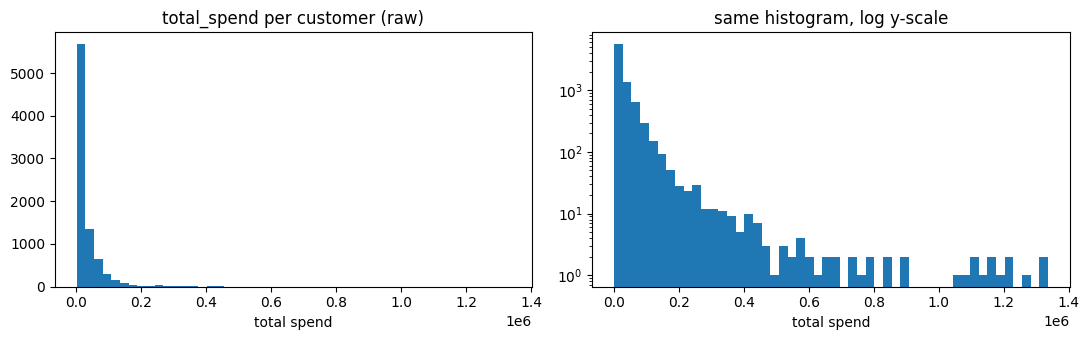

In [7]:
%matplotlib inline
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(customers["total_spend"], bins=50)
axes[0].set_title("total_spend per customer (raw)")
axes[0].set_xlabel("total spend")
axes[1].hist(customers["total_spend"], bins=50, log=True)
axes[1].set_title("same histogram, log y-scale")
axes[1].set_xlabel("total spend")
plt.tight_layout()
plt.show()

In [8]:
customers["order_count"].value_counts().sort_index().head(10)

order_count
1     4679
2      403
3      378
4      471
5      445
6      453
7      338
8      276
9      198
10     126
Name: count, dtype: int64

## 4. Time span, channels, lifecycle

Sanity checks for Milestone 2: the window should be ~3 months, and the
paid-customer count should land between 8K and 15K.

In [9]:
print("first order:", customers["first_order_date"].min())
print("last order: ", customers["last_order_date"].max())
pd.read_sql(
    sa.text(
        "SELECT lifecycle_stage, COUNT(*) AS n FROM ecom.customers "
        "GROUP BY 1 ORDER BY n DESC"
    ),
    engine,
)


first order: 2026-03-16 00:13:57+00:00
last order:  2026-06-14 23:28:40+00:00


,lifecycle_stage,n
0,active,4869
1,at_risk,3903
2,new,1200
3,churned,28


In [10]:
pd.read_sql(
    sa.text(
        "SELECT acquisition_channel, COUNT(*) AS n FROM ecom.customers "
        "GROUP BY 1 ORDER BY n DESC"
    ),
    engine,
)

,acquisition_channel,n
0,organic,4023
1,paid,3490
2,referral,1192
3,email,708
4,affiliate,587


## Notes (wrong turns kept on purpose)

- I first aggregated **all** orders including `cancelled/failed`, which added
  ~2,178 unpaid orders and inflated customer counts. Dropped: spend must be
  `payment_status = 'paid'` only.
- `status` has case variants (`shipped` vs `Shipped` vs `SHIPPED`, same for
  `delivered`). Fulfilment analysis in a later milestone should normalise
  with `LOWER(status)` first — flagged, not fixed here.

Takeaway for Milestone 3: most customers are one-timers, but a heavy-repeat
minority (≈35% with 4+ orders) plus a long right tail of big spenders will
dominate any segmentation. RFM features must separate recency/frequency
from raw monetary, or the whales will swallow every segment.